<a href="https://colab.research.google.com/github/Vidit-01/pedestrian_intent_prediction/blob/yash/experiments/paper1_vlfm_jaad/notebooks/03_extract_video_frames.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:

from pathlib import Path
import json
import re
import pandas as pd

REPO_ROOT = Path("/content/pedestrian_intent_prediction")
JAAD_ROOT = Path("/content/JAAD")

EXP_ROOT = (
    REPO_ROOT
    / "experiments"
    / "paper1_vlfm_jaad"
)

RESULTS_DIR = EXP_ROOT / "results"
CONFIGS_DIR = EXP_ROOT / "configs"

MANIFEST_PATH = (
    RESULTS_DIR / "jaad_16x16_sample_manifest.csv"
)

FRAME_OUTPUT_DIR = (
    RESULTS_DIR / "extracted_frames"
)

FRAME_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Manifest not found: {MANIFEST_PATH}\n"
        "Complete Notebook 02 and save its output first."
    )

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest rows:", len(manifest))
print("Columns:", manifest.columns.tolist())
print("\nSamples per split:")
print(manifest["split"].value_counts())


Manifest rows: 607
Columns: ['sample_id', 'split', 'video_id', 'pedestrian_id', 'parser_sequence_index', 'parser_sequence_length', 'observation_start_position', 'observation_end_position_exclusive', 'target_start_position', 'target_end_position_exclusive', 'observation_frame_count', 'prediction_horizon_frame_count', 'intention_label', 'label_definition', 'observation_image_refs_json', 'target_window_image_refs_json', 'observation_bboxes_json', 'target_window_bboxes_json', 'assumed_fps', 'sample_policy']

Samples per split:
split
train    295
test     265
val       47
Name: count, dtype: int64


In [37]:

video_roots = [
    JAAD_ROOT / "JAAD_clips",
    JAAD_ROOT / "videos",
    JAAD_ROOT,
]

video_extensions = {".mp4", ".avi", ".mov", ".mkv"}
video_files = []

for root in video_roots:
    if root.exists():
        video_files.extend(
            p for p in root.rglob("*")
            if p.is_file() and p.suffix.lower() in video_extensions
        )

# Remove duplicate paths.
video_files = sorted(set(video_files))

print("Video files found:", len(video_files))

for path in video_files[:10]:
    print(path, f"({path.stat().st_size / 1e6:.1f} MB)")

video_lookup = {}

for path in video_files:
    match = re.search(r"video_\d+", path.stem)
    if match:
        video_lookup.setdefault(match.group(0), path)

required_videos = set(manifest["video_id"].dropna().astype(str))
missing_videos = sorted(required_videos - set(video_lookup))

print("\nUnique videos required by manifest:", len(required_videos))
print("Matching video files:", len(required_videos & set(video_lookup)))
print("Missing video files:", len(missing_videos))

if missing_videos:
    print("Examples:", missing_videos[:20])


Video files found: 346
/content/JAAD/JAAD_clips/video_0001.mp4 (6.9 MB)
/content/JAAD/JAAD_clips/video_0002.mp4 (5.4 MB)
/content/JAAD/JAAD_clips/video_0003.mp4 (4.5 MB)
/content/JAAD/JAAD_clips/video_0004.mp4 (4.0 MB)
/content/JAAD/JAAD_clips/video_0005.mp4 (5.2 MB)
/content/JAAD/JAAD_clips/video_0006.mp4 (8.2 MB)
/content/JAAD/JAAD_clips/video_0007.mp4 (5.0 MB)
/content/JAAD/JAAD_clips/video_0008.mp4 (3.2 MB)
/content/JAAD/JAAD_clips/video_0009.mp4 (3.0 MB)
/content/JAAD/JAAD_clips/video_0010.mp4 (3.0 MB)

Unique videos required by manifest: 297
Matching video files: 297
Missing video files: 0


In [33]:

required_columns = [
    "video_id",
    "observation_image_refs_json",
    "target_window_image_refs_json",
]

missing_columns = [
    c for c in required_columns
    if c not in manifest.columns
]

if missing_columns:
    raise ValueError(
        f"Manifest is missing required columns: {missing_columns}"
    )

for _, row in manifest.head(3).iterrows():
    print("\nSample:", row["sample_id"])
    print("Video:", row["video_id"])

    observed = json.loads(row["observation_image_refs_json"])
    target = json.loads(row["target_window_image_refs_json"])

    print("Observed frame-reference count:", len(observed))
    print("First observed references:", observed[:3])
    print("Last observed reference:", observed[-1] if observed else None)
    print("First target reference:", target[0] if target else None)
    print("Last target reference:", target[-1] if target else None)



Sample: train_d2d2e6787a5b
Video: video_0001
Observed frame-reference count: 16
First observed references: ['/content/JAAD/images/video_0001/00332.png', '/content/JAAD/images/video_0001/00333.png', '/content/JAAD/images/video_0001/00334.png']
Last observed reference: /content/JAAD/images/video_0001/00347.png
First target reference: /content/JAAD/images/video_0001/00348.png
Last target reference: /content/JAAD/images/video_0001/00363.png

Sample: train_00e83cc2b263
Video: video_0003
Observed frame-reference count: 16
First observed references: ['/content/JAAD/images/video_0003/00141.png', '/content/JAAD/images/video_0003/00142.png', '/content/JAAD/images/video_0003/00143.png']
Last observed reference: /content/JAAD/images/video_0003/00156.png
First target reference: /content/JAAD/images/video_0003/00157.png
Last target reference: /content/JAAD/images/video_0003/00172.png

Sample: train_695daa3de06e
Video: video_0004
Observed frame-reference count: 16
First observed references: ['/conte

In [38]:
%pip -q install opencv-python-headless

In [35]:

import cv2

video_audit = []

for video_id in sorted(required_videos):
    path = video_lookup.get(video_id)

    if path is None:
        video_audit.append({
            "video_id": video_id,
            "path": None,
            "readable": False,
            "fps": None,
            "frame_count": None,
            "width": None,
            "height": None,
        })
        continue

    cap = cv2.VideoCapture(str(path))

    readable = cap.isOpened()
    fps = cap.get(cv2.CAP_PROP_FPS) if readable else None
    frame_count = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    ) if readable else None
    width = int(
        cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    ) if readable else None
    height = int(
        cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
    ) if readable else None

    if readable:
        ok, frame = cap.read()
        readable = bool(ok and frame is not None)

    cap.release()

    video_audit.append({
        "video_id": video_id,
        "path": str(path),
        "readable": readable,
        "fps": fps,
        "frame_count": frame_count,
        "width": width,
        "height": height,
    })

video_audit_df = pd.DataFrame(video_audit)

display(video_audit_df.head(10))
print("\nReadable videos:", int(video_audit_df["readable"].sum()))
print("Videos required:", len(required_videos))

audit_path = RESULTS_DIR / "video_preflight_audit.csv"
video_audit_df.to_csv(audit_path, index=False)
print("Saved:", audit_path)


,video_id,path,readable,fps,frame_count,width,height
0,video_0001,None,False,None,None,None,None
1,video_0003,None,False,None,None,None,None
2,video_0004,None,False,None,None,None,None
3,video_0005,None,False,None,None,None,None
4,video_0006,None,False,None,None,None,None
5,video_0007,None,False,None,None,None,None
6,video_0008,None,False,None,None,None,None
7,video_0011,None,False,None,None,None,None
8,video_0012,None,False,None,None,None,None
9,video_0014,None,False,None,None,None,None



Readable videos: 0
Videos required: 297
Saved: /content/pedestrian_intent_prediction/experiments/paper1_vlfm_jaad/results/video_preflight_audit.csv


In [36]:

from pathlib import Path
import subprocess
import zipfile

JAAD_ROOT = Path("/content/JAAD")
CLIPS_DIR = JAAD_ROOT / "JAAD_clips"
ZIP_PATH = Path("/content/JAAD_clips.zip")

CLIPS_DIR.mkdir(parents=True, exist_ok=True)

# Skip downloading if the clips already exist.
existing = list(CLIPS_DIR.glob("video_*.mp4"))

if existing:
    print(f"Found {len(existing)} existing video clips.")
else:
    url = (
        "https://data.nvision2.eecs.yorku.ca/"
        "JAAD_dataset/data/JAAD_clips.zip"
    )

    print("Downloading official JAAD video archive...")
    result = subprocess.run(
        ["wget", "-c", "-O", str(ZIP_PATH), url],
        check=False
    )

    if result.returncode != 0 or not ZIP_PATH.exists() or ZIP_PATH.stat().st_size == 0:
        raise RuntimeError(
            "Download failed. Try the official Google Drive link "
            "listed in the JAAD 2.0 README."
        )

    print(f"Archive size: {ZIP_PATH.stat().st_size / 1e9:.2f} GB")

    print("Checking archive...")
    if not zipfile.is_zipfile(ZIP_PATH):
        raise RuntimeError(
            "Downloaded file is not a valid ZIP archive. "
            "Do not attempt extraction."
        )

    print("Extracting clips...")
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(JAAD_ROOT)

    # Handle archives that contain an extra enclosing directory.
    nested = list(JAAD_ROOT.rglob("video_0001.mp4"))
    if not (CLIPS_DIR / "video_0001.mp4").exists() and nested:
        print("Example clip found at:", nested[0])

    existing = list(CLIPS_DIR.glob("video_*.mp4"))

    print("MP4 clips in expected directory:", len(existing))
    print("Expected directory:", CLIPS_DIR)


Archive size: 3.08 GB
Checking archive...
Extracting clips...
MP4 clips in expected directory: 346
Expected directory: /content/JAAD/JAAD_clips


In [39]:
import cv2
import pandas as pd

video_audit = []

for video_id in sorted(required_videos):
    path = video_lookup.get(video_id)

    cap = cv2.VideoCapture(str(path))
    opened = cap.isOpened()

    fps = cap.get(cv2.CAP_PROP_FPS) if opened else None
    frame_count = (
        int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if opened else None
    )
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) if opened else None
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) if opened else None

    ok, frame = cap.read() if opened else (False, None)
    readable = bool(ok and frame is not None)
    cap.release()

    video_audit.append({
        "video_id": video_id,
        "path": str(path),
        "readable": readable,
        "fps": fps,
        "frame_count": frame_count,
        "width": width,
        "height": height,
    })

video_audit_df = pd.DataFrame(video_audit)

display(video_audit_df.head(10))

print("Readable videos:", int(video_audit_df["readable"].sum()))
print("Videos required:", len(required_videos))
print("FPS values:", sorted(video_audit_df["fps"].dropna().unique().tolist()))

audit_path = RESULTS_DIR / "video_preflight_audit.csv"
video_audit_df.to_csv(audit_path, index=False)
print("Saved:", audit_path)

,video_id,path,readable,fps,frame_count,width,height
0,video_0001,/content/JAAD/JAAD_clips/video_0001.mp4,True,29.97003,600,1920,1080
1,video_0003,/content/JAAD/JAAD_clips/video_0003.mp4,True,29.97003,210,1920,1080
2,video_0004,/content/JAAD/JAAD_clips/video_0004.mp4,True,29.97003,180,1920,1080
3,video_0005,/content/JAAD/JAAD_clips/video_0005.mp4,True,29.97003,240,1920,1080
4,video_0006,/content/JAAD/JAAD_clips/video_0006.mp4,True,29.97003,330,1920,1080
5,video_0007,/content/JAAD/JAAD_clips/video_0007.mp4,True,29.97003,120,1920,1080
6,video_0008,/content/JAAD/JAAD_clips/video_0008.mp4,True,29.97003,150,1920,1080
7,video_0011,/content/JAAD/JAAD_clips/video_0011.mp4,True,29.97003,270,1920,1080
8,video_0012,/content/JAAD/JAAD_clips/video_0012.mp4,True,29.97003,120,1920,1080
9,video_0014,/content/JAAD/JAAD_clips/video_0014.mp4,True,29.97003,270,1920,1080


Readable videos: 297
Videos required: 297
FPS values: [29.97002997002997, 30.0, 59.94005994005994]
Saved: /content/pedestrian_intent_prediction/experiments/paper1_vlfm_jaad/results/video_preflight_audit.csv


In [40]:

import json
import re
import cv2
import pandas as pd
from pathlib import Path

# Inspect up to three samples from the manifest.
for _, row in manifest.head(3).iterrows():
    video_id = str(row["video_id"])
    video_path = video_lookup[video_id]

    obs_refs = json.loads(row["observation_image_refs_json"])
    target_refs = json.loads(row["target_window_image_refs_json"])

    cap = cv2.VideoCapture(str(video_path))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    cap.release()

    print("\n" + "=" * 70)
    print("Sample ID:", row["sample_id"])
    print("Video ID:", video_id)
    print("Video frame count:", frame_count)
    print("Video FPS:", fps)

    print("\nObservation references:")
    print("Count:", len(obs_refs))
    print("First 3:", obs_refs[:3])
    print("Last 3:", obs_refs[-3:])

    print("\nTarget references (audit only; never model input):")
    print("Count:", len(target_refs))
    print("First 3:", target_refs[:3])
    print("Last 3:", target_refs[-3:])

    # Extract numeric tokens only for diagnosis; do not assume
    # they are already zero-based OpenCV frame indices.
    combined = obs_refs + target_refs
    numeric_tokens = []

    for ref in combined:
        nums = re.findall(r"\d+", str(ref))
        numeric_tokens.append(nums[-1] if nums else None)

    print("\nNumeric tokens from references:")
    print(numeric_tokens[:5], "...", numeric_tokens[-5:])



Sample ID: train_d2d2e6787a5b
Video ID: video_0001
Video frame count: 600
Video FPS: 29.97002997002997

Observation references:
Count: 16
First 3: ['/content/JAAD/images/video_0001/00332.png', '/content/JAAD/images/video_0001/00333.png', '/content/JAAD/images/video_0001/00334.png']
Last 3: ['/content/JAAD/images/video_0001/00345.png', '/content/JAAD/images/video_0001/00346.png', '/content/JAAD/images/video_0001/00347.png']

Target references (audit only; never model input):
Count: 16
First 3: ['/content/JAAD/images/video_0001/00348.png', '/content/JAAD/images/video_0001/00349.png', '/content/JAAD/images/video_0001/00350.png']
Last 3: ['/content/JAAD/images/video_0001/00361.png', '/content/JAAD/images/video_0001/00362.png', '/content/JAAD/images/video_0001/00363.png']

Numeric tokens from references:
['00332', '00333', '00334', '00335', '00336'] ... ['00359', '00360', '00361', '00362', '00363']

Sample ID: train_00e83cc2b263
Video ID: video_0003
Video frame count: 210
Video FPS: 29.970

In [41]:

import json
import re
import cv2
import pandas as pd
from pathlib import Path

FRAME_OUTPUT_DIR = RESULTS_DIR / "extracted_frames"
FRAME_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FRAME_REF_COL = "observation_image_refs_json"

assert FRAME_REF_COL in manifest.columns, (
    f"Missing {FRAME_REF_COL}. Columns: {manifest.columns.tolist()}"
)

extraction_audit = []

for _, row in manifest.iterrows():
    sample_id = str(row["sample_id"])
    video_id = str(row["video_id"])
    video_path = video_lookup.get(video_id)

    if video_path is None:
        extraction_audit.append({
            "sample_id": sample_id,
            "video_id": video_id,
            "status": "missing_video",
            "expected_frames": 16,
            "extracted_frames": 0,
            "details": "No matching video file",
        })
        continue

    refs = json.loads(row[FRAME_REF_COL])

    if len(refs) != 16:
        extraction_audit.append({
            "sample_id": sample_id,
            "video_id": video_id,
            "status": "invalid_observation_count",
            "expected_frames": 16,
            "extracted_frames": 0,
            "details": f"Found {len(refs)} references",
        })
        continue

    sample_dir = FRAME_OUTPUT_DIR / sample_id
    sample_dir.mkdir(parents=True, exist_ok=True)

    cap = cv2.VideoCapture(str(video_path))
    saved = 0
    errors = []

    for i, ref in enumerate(refs):
        # JAAD's official image naming uses zero-based frame numbers.
        match = re.search(r"(\d+)\.png$", str(ref))

        if not match:
            errors.append(f"Unrecognized frame reference: {ref}")
            continue

        frame_idx = int(match.group(1))
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if not 0 <= frame_idx < frame_count:
            errors.append(
                f"Out-of-range frame index {frame_idx}; "
                f"video has {frame_count} frames"
            )
            continue

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ok, frame = cap.read()

        if not ok or frame is None:
            errors.append(f"Could not decode frame {frame_idx}")
            continue

        output_path = sample_dir / f"obs_{i:02d}.png"

        if not cv2.imwrite(str(output_path), frame):
            errors.append(f"Could not save {output_path}")
            continue

        saved += 1

    cap.release()

    extraction_audit.append({
        "sample_id": sample_id,
        "video_id": video_id,
        "status": "ok" if saved == 16 and not errors else "partial_or_failed",
        "expected_frames": 16,
        "extracted_frames": saved,
        "details": "; ".join(errors),
    })

audit_df = pd.DataFrame(extraction_audit)
audit_path = RESULTS_DIR / "frame_extraction_audit.csv"
audit_df.to_csv(audit_path, index=False)

print("Samples in manifest:", len(manifest))
print("Fully extracted samples:", int((audit_df["status"] == "ok").sum()))
print("Failed/partial samples:", int((audit_df["status"] != "ok").sum()))
print("Total observation frames saved:", int(audit_df["extracted_frames"].sum()))
print("Audit saved to:", audit_path)

display(audit_df[audit_df["status"] != "ok"].head(10))


KeyboardInterrupt: 

In [42]:

from pathlib import Path
import pandas as pd

FRAME_OUTPUT_DIR = RESULTS_DIR / "extracted_frames"

sample_dirs = [
    p for p in FRAME_OUTPUT_DIR.iterdir()
    if p.is_dir()
]

saved_frames = sum(
    1 for p in FRAME_OUTPUT_DIR.rglob("obs_*.png")
    if p.is_file()
)

print("Sample directories created:", len(sample_dirs))
print("Observation frames saved:", saved_frames)
print("Expected frames:", len(manifest) * 16)

if saved_frames:
    print("Approximate completion:", f"{100 * saved_frames / (len(manifest) * 16):.1f}%")


Sample directories created: 560
Observation frames saved: 8949
Expected frames: 9712
Approximate completion: 92.1%


In [43]:

import json
import re
import cv2
import pandas as pd
from collections import defaultdict

FRAME_OUTPUT_DIR = RESULTS_DIR / "extracted_frames"
FRAME_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

samples_by_video = defaultdict(list)

for _, row in manifest.iterrows():
    samples_by_video[str(row["video_id"])].append(row)

resume_audit = []

for video_num, (video_id, rows) in enumerate(
    samples_by_video.items(), start=1
):
    video_path = video_lookup.get(video_id)

    if video_path is None:
        print(f"Missing video: {video_id}")
        continue

    # Map each required frame index to all missing output files that need it.
    needed = defaultdict(list)

    for row in rows:
        sample_id = str(row["sample_id"])
        refs = json.loads(row["observation_image_refs_json"])
        sample_dir = FRAME_OUTPUT_DIR / sample_id

        if len(refs) != 16:
            resume_audit.append({
                "sample_id": sample_id,
                "video_id": video_id,
                "status": "invalid_reference_count",
                "saved_frames": 0,
            })
            continue

        for i, ref in enumerate(refs):
            out_path = sample_dir / f"obs_{i:02d}.png"

            # Resume safely: preserve existing, nonempty files.
            if out_path.exists() and out_path.stat().st_size > 0:
                continue

            match = re.search(r"(\d+)\.png$", str(ref))
            if match:
                frame_idx = int(match.group(1))
                needed[frame_idx].append((out_path, sample_id))

    if not needed:
        continue

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        cap.release()
        print(f"Could not open: {video_id}")
        continue

    max_needed = max(needed)
    saved_this_video = 0
    failed_this_video = 0
    frame_idx = 0

    # Sequential decoding; only write frames that are still missing.
    while frame_idx <= max_needed:
        ok, frame = cap.read()

        if not ok:
            break

        for out_path, sample_id in needed.get(frame_idx, []):
            out_path.parent.mkdir(parents=True, exist_ok=True)

            if cv2.imwrite(str(out_path), frame):
                saved_this_video += 1
            else:
                failed_this_video += 1

        frame_idx += 1

    cap.release()

    print(
        f"[{video_num}/{len(samples_by_video)}] {video_id}: "
        f"{saved_this_video} saved, {failed_this_video} failed"
    )

# Verify the final state by checking all 16 expected files per sample.
for _, row in manifest.iterrows():
    sample_id = str(row["sample_id"])
    sample_dir = FRAME_OUTPUT_DIR / sample_id

    saved_count = sum(
        (sample_dir / f"obs_{i:02d}.png").exists()
        and (sample_dir / f"obs_{i:02d}.png").stat().st_size > 0
        for i in range(16)
    )

    resume_audit.append({
        "sample_id": sample_id,
        "video_id": str(row["video_id"]),
        "status": "ok" if saved_count == 16 else "incomplete",
        "saved_frames": int(saved_count),
    })

final_audit = (
    pd.DataFrame(resume_audit)
    .drop_duplicates(subset=["sample_id"], keep="last")
)

final_audit.to_csv(
    RESULTS_DIR / "frame_extraction_audit.csv",
    index=False
)

complete = int((final_audit["status"] == "ok").sum())
total = len(manifest)

print("\nFINAL EXTRACTION CHECK")
print(f"Complete samples: {complete}/{total}")
print(f"Expected frames: {total * 16}")
print(f"Frames present: {int(final_audit['saved_frames'].sum())}")
print(f"Incomplete samples: {total - complete}")
print("Audit:", RESULTS_DIR / "frame_extraction_audit.csv")


[281/297] video_0307: 27 saved, 0 failed
[282/297] video_0308: 16 saved, 0 failed
[283/297] video_0309: 80 saved, 0 failed
[284/297] video_0313: 176 saved, 0 failed
[285/297] video_0314: 64 saved, 0 failed
[286/297] video_0316: 16 saved, 0 failed
[287/297] video_0322: 16 saved, 0 failed
[288/297] video_0327: 112 saved, 0 failed
[289/297] video_0329: 16 saved, 0 failed
[290/297] video_0330: 32 saved, 0 failed
[291/297] video_0332: 48 saved, 0 failed
[292/297] video_0333: 16 saved, 0 failed
[293/297] video_0334: 32 saved, 0 failed
[294/297] video_0336: 48 saved, 0 failed
[295/297] video_0338: 32 saved, 0 failed
[296/297] video_0339: 16 saved, 0 failed
[297/297] video_0344: 16 saved, 0 failed

FINAL EXTRACTION CHECK
Complete samples: 607/607
Expected frames: 9712
Frames present: 9712
Incomplete samples: 0
Audit: /content/pedestrian_intent_prediction/experiments/paper1_vlfm_jaad/results/frame_extraction_audit.csv


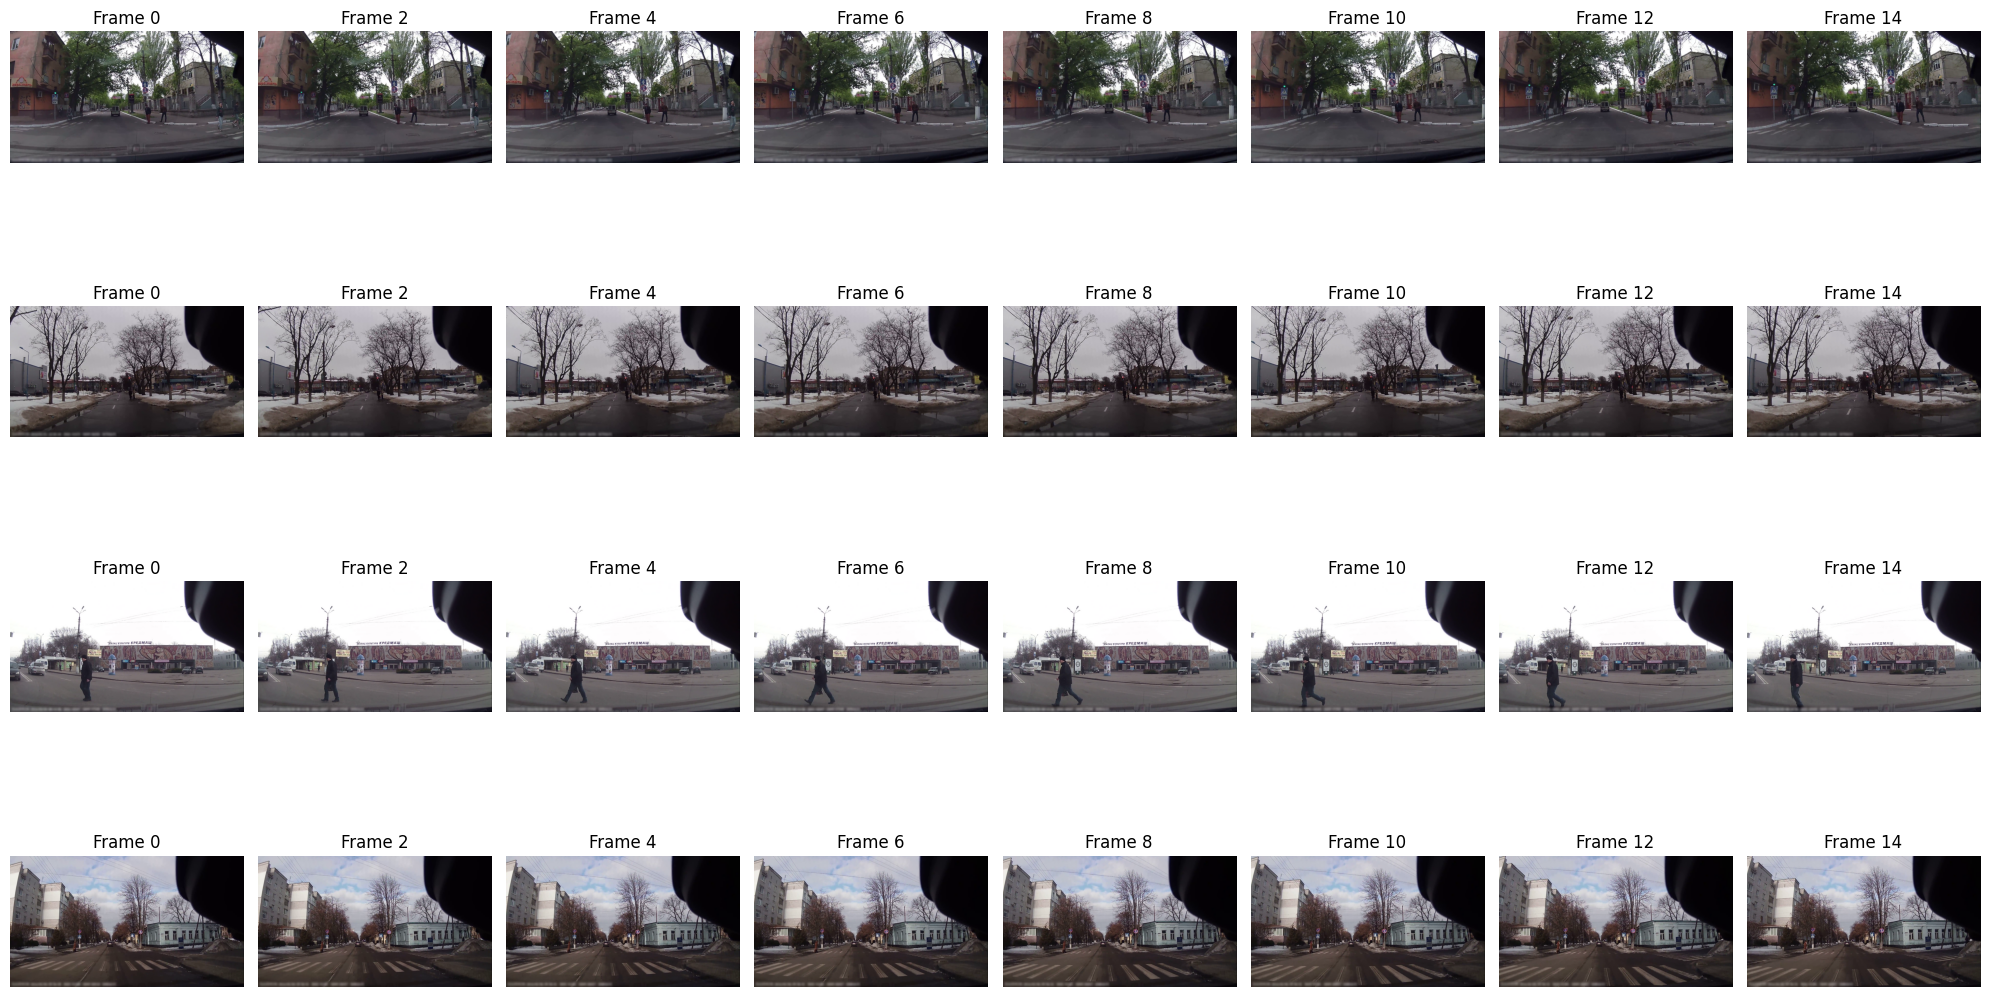

In [44]:

import json
import random
import math
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

FRAME_OUTPUT_DIR = RESULTS_DIR / "extracted_frames"

# Reproducible sample selection
rng = random.Random(42)
n = min(4, len(manifest))
selected = manifest.sample(n=n, random_state=42)

fig, axes = plt.subplots(n, 8, figsize=(20, 3 * n))

if n == 1:
    axes = [axes]

for row_idx, (_, row) in enumerate(selected.iterrows()):
    sample_id = str(row["sample_id"])
    sample_dir = FRAME_OUTPUT_DIR / sample_id

    # Display 8 evenly spaced frames from the 16-frame observation window.
    frame_positions = [0, 2, 4, 6, 8, 10, 12, 14]

    for col_idx, frame_pos in enumerate(frame_positions):
        frame_path = sample_dir / f"obs_{frame_pos:02d}.png"
        image = cv2.imread(str(frame_path))

        ax = axes[row_idx][col_idx]
        ax.axis("off")

        if image is None:
            ax.set_title(f"Missing {frame_pos}")
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        ax.imshow(image)
        ax.set_title(f"Frame {frame_pos}")

    axes[row_idx][0].set_ylabel(
        sample_id[:18],
        rotation=90,
        labelpad=10
    )

plt.tight_layout()
plt.show()


In [45]:

print("Manifest columns:")
for col in manifest.columns:
    if any(term in col.lower() for term in [
        "bbox", "box", "pedestrian", "track", "frame", "image_ref"
    ]):
        print(f"- {col}")

print("\nExample sample metadata:")
display(manifest.iloc[0].to_frame("value"))


Manifest columns:
- pedestrian_id
- observation_frame_count
- prediction_horizon_frame_count
- observation_image_refs_json
- target_window_image_refs_json
- observation_bboxes_json
- target_window_bboxes_json

Example sample metadata:


,value
sample_id,train_d2d2e6787a5b
split,train
video_id,video_0001
pedestrian_id,0_1_3b
parser_sequence_index,1
parser_sequence_length,364
observation_start_position,332
observation_end_position_exclusive,348
target_start_position,348
target_end_position_exclusive,364


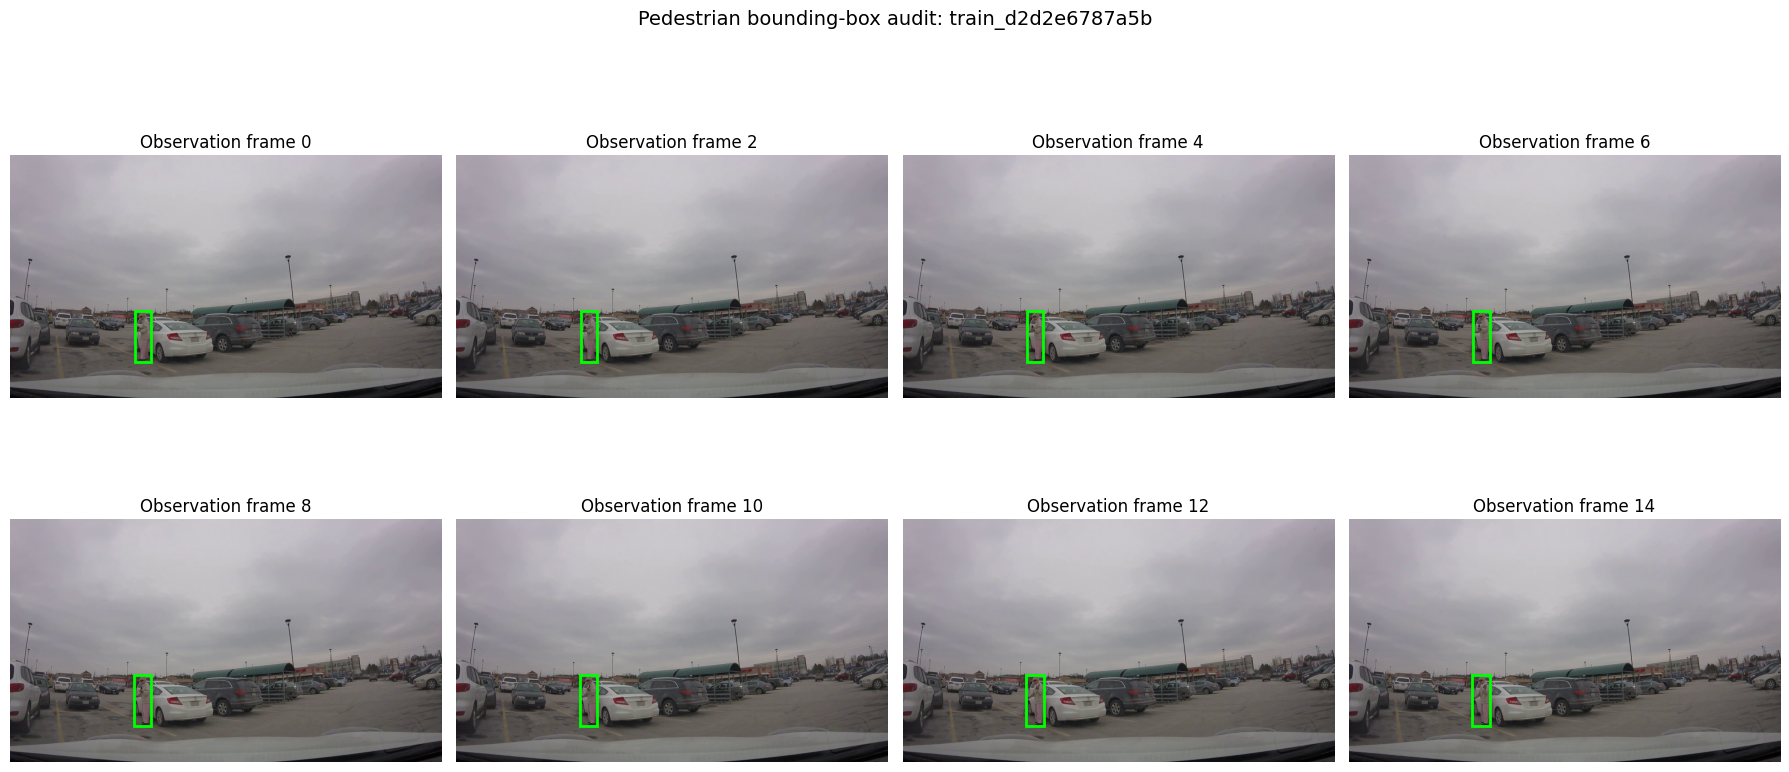

In [46]:

import json
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

FRAME_OUTPUT_DIR = RESULTS_DIR / "extracted_frames"

# Choose a reproducible sample.
sample = manifest.iloc[0]

sample_id = str(sample["sample_id"])
bboxes = json.loads(sample["observation_bboxes_json"])
sample_dir = FRAME_OUTPUT_DIR / sample_id

# Show 8 frames across the 16-frame observation window.
frame_positions = [0, 2, 4, 6, 8, 10, 12, 14]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for ax, frame_pos in zip(axes, frame_positions):
    frame_path = sample_dir / f"obs_{frame_pos:02d}.png"
    image = cv2.imread(str(frame_path))

    ax.axis("off")

    if image is None:
        ax.set_title(f"Missing frame {frame_pos}")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    # JAAD boxes are represented as [x1, y1, x2, y2].
    x1, y1, x2, y2 = map(float, bboxes[frame_pos])

    # Report boxes that fall outside the image.
    valid = (
        0 <= x1 < x2 <= width
        and 0 <= y1 < y2 <= height
    )

    ax.imshow(image)

    if valid:
        rect = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="lime",
            linewidth=2,
        )
        ax.add_patch(rect)
    else:
        ax.set_title(f"Frame {frame_pos}: CHECK BOX")
        print(
            f"Invalid box: sample={sample_id}, "
            f"frame={frame_pos}, box={[x1, y1, x2, y2]}, "
            f"image_size={(width, height)}"
        )

    ax.set_title(f"Observation frame {frame_pos}")

plt.suptitle(
    f"Pedestrian bounding-box audit: {sample_id}",
    fontsize=14,
)
plt.tight_layout()
plt.show()


In [47]:

import json
import cv2
import pandas as pd

FRAME_OUTPUT_DIR = RESULTS_DIR / "extracted_frames"

audit_rows = []

for _, row in manifest.iterrows():
    sample_id = str(row["sample_id"])
    bboxes = json.loads(row["observation_bboxes_json"])
    sample_dir = FRAME_OUTPUT_DIR / sample_id

    for i, bbox in enumerate(bboxes):
        frame_path = sample_dir / f"obs_{i:02d}.png"
        image = cv2.imread(str(frame_path))

        if image is None:
            audit_rows.append({
                "sample_id": sample_id,
                "frame_position": i,
                "status": "missing_image",
            })
            continue

        height, width = image.shape[:2]
        x1, y1, x2, y2 = map(float, bbox)
        box_w = x2 - x1
        box_h = y2 - y1

        valid = (
            0 <= x1 < x2 <= width
            and 0 <= y1 < y2 <= height
        )

        audit_rows.append({
            "sample_id": sample_id,
            "frame_position": i,
            "image_width": width,
            "image_height": height,
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
            "box_width": box_w,
            "box_height": box_h,
            "aspect_ratio_h_over_w": (
                box_h / box_w if box_w > 0 else None
            ),
            "box_area_fraction": (
                box_w * box_h / (width * height)
                if box_w > 0 and box_h > 0 else None
            ),
            "status": "ok" if valid else "invalid_coordinates",
        })

bbox_audit = pd.DataFrame(audit_rows)

print("Total boxes:", len(bbox_audit))
print("Invalid coordinates:", int(
    (bbox_audit["status"] == "invalid_coordinates").sum()
))
print("Missing images:", int(
    (bbox_audit["status"] == "missing_image").sum()
))

print("\nBounding-box dimensions:")
display(
    bbox_audit[
        ["box_width", "box_height", "aspect_ratio_h_over_w"]
    ].describe()
)

print("\nFirst 20 unusual boxes (if any):")
unusual = bbox_audit[
    (bbox_audit["status"] != "ok")
    | (bbox_audit["box_width"] < 10)
    | (bbox_audit["box_height"] < 20)
    | (bbox_audit["aspect_ratio_h_over_w"] < 1)
]

display(unusual.head(20))

bbox_audit.to_csv(
    RESULTS_DIR / "observation_bbox_audit.csv",
    index=False
)
print("\nSaved:", RESULTS_DIR / "observation_bbox_audit.csv")


Total boxes: 9712
Invalid coordinates: 0
Missing images: 0

Bounding-box dimensions:


,box_width,box_height,aspect_ratio_h_over_w
count,9712.000000,9712.000000,9712.000000
mean,84.694811,210.307146,2.587275
std,50.101137,112.940682,0.565227
min,10.000000,33.000000,1.222222
25%,48.000000,125.000000,2.200000
50%,71.000000,178.500000,2.540000
75%,111.000000,283.250000,2.890271
max,312.000000,555.000000,7.887097



First 20 unusual boxes (if any):


,sample_id,frame_position,image_width,image_height,x1,y1,x2,y2,box_width,box_height,aspect_ratio_h_over_w,box_area_fraction,status



Saved: /content/pedestrian_intent_prediction/experiments/paper1_vlfm_jaad/results/observation_bbox_audit.csv


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

successful_ids = audit_df.loc[
    audit_df["status"] == "ok", "sample_id"
].tolist()

if not successful_ids:
    raise RuntimeError("No samples extracted successfully.")

sample_id = successful_ids[0]
sample_dir = FRAME_OUTPUT_DIR / sample_id

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for i, ax in enumerate(axes.flat):
    image_path = sample_dir / f"obs_{i:02d}.png"
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(f"Observation frame {i + 1}")
    ax.axis("off")

plt.suptitle(f"Sample: {sample_id} — observation frames only")
plt.tight_layout()
plt.show()


In [ ]:

print("Manifest columns:")
for col in manifest.columns:
    print("-", col)

box_candidates = [
    col for col in manifest.columns
    if "box" in col.lower() or "bbox" in col.lower()
]

print("\nBounding-box candidate columns:", box_candidates)

for col in box_candidates:
    print(f"\nColumn: {col}")
    print(manifest[col].iloc[0])
